# 03 · Customer intelligence: churn prediction + RFM segments + identity capture

**Business problem.** Cottonil's customers rarely announce they are leaving. The goal is to know **who is about to lapse
while we can still win them back**, how valuable they are, and what to do about each segment.
A second problem: ~19% of orders have **no customer ID**, so those shoppers are invisible to CRM.

**Plan**
1. *Snapshot* design: at every quarter-end we look only at the past (RFM-style features) and label whether the customer
   **did not buy in the next 120 days**. (120 days is checked below against the real purchase-gap distribution.)
2. **HistGradientBoosting** classifier vs a simple *recency-only* baseline, evaluated on the most recent snapshots.
3. Rule-based **RFM segments** + recommended action + **value at risk** = P(churn) × last-12-month spend.
4. **Where do we lose identities?** anonymous-order share by branch/channel (the practical fix is loyalty capture at the till).

We deliberately did **not** build a graph-neural-network "identity matcher": the dataset has no card token / phone / device keys to match on,
so any such model would have nothing real to learn from. Capturing the ID at checkout is cheaper and more effective.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                       # lets the notebook import the `cottonil` package
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cottonil import config as cfg
from cottonil.data_io import load_table, load_sales_lines, load_product_master, week_start, quick_profile
from cottonil.plotting import setup, NAVY, TEAL, ORANGE, RED, PALETTE
setup()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

DATA_DIR = cfg.find_data_dir()
SOURCE = cfg.data_source(DATA_DIR)
print(f"Data folder : {DATA_DIR}")
print(f"Data source : {SOURCE.upper()}" + ("   <-- synthetic test data; retrain on real data before trusting any number" if SOURCE == "synthetic" else ""))

Data folder : D:\HVIA Internship\task 2\cottonil-ai\COTTONIL_Data
Data source : REAL


In [2]:
from cottonil import customers as C
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

orders = load_table("sales_orders"); customers = load_table("customers")
o = orders.rename(columns={"net_before_tax_EGP": "net", "items_count": "items", "sales_channel": "channel"})
ident = o[o.customer_id.notna()][["customer_id", "order_date", "net", "items", "channel"]].copy()
last_date = orders.order_date.max()
print(f"identified orders: {len(ident):,} ({len(ident) / len(orders):.1%}) by {ident.customer_id.nunique():,} customers | data ends {last_date.date()}")

identified orders: 437,039 (80.9%) by 74,660 customers | data ends 2026-10-18


## 1 · Is 120 days a sensible churn horizon?
Distribution of days between consecutive orders of the same customer:

gap quantiles (days): {0.5: 147.0, 0.75: 314.0, 0.9: 536.0, 0.95: 703.0}


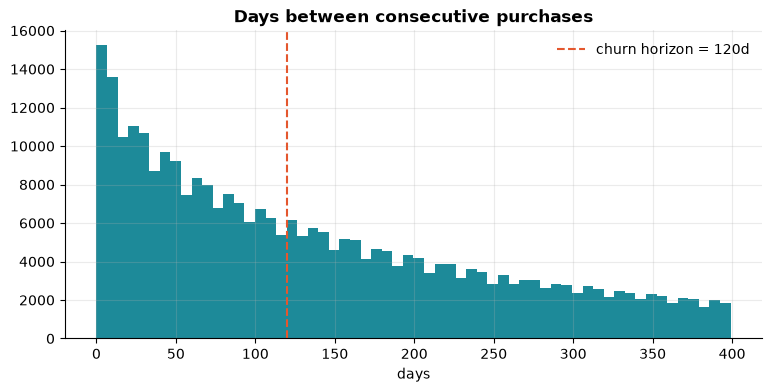

share of repeat gaps longer than 120 days: 56.1%


In [3]:
s = ident.sort_values(["customer_id", "order_date"])
gap = s.groupby("customer_id").order_date.diff().dt.days.dropna()
q = gap.quantile([.5, .75, .9, .95]).round(0)
print("gap quantiles (days):", q.to_dict())
gap[gap < 400].hist(bins=60, color=TEAL); plt.axvline(C.CHURN_DAYS, color=RED, ls="--", label=f"churn horizon = {C.CHURN_DAYS}d")
plt.legend(); plt.title("Days between consecutive purchases"); plt.xlabel("days"); plt.show()
print(f"share of repeat gaps longer than {C.CHURN_DAYS} days: {(gap > C.CHURN_DAYS).mean():.1%}")

**Reading it.** If the horizon is far *shorter* than typical gaps, most customers look churned by construction;
far *longer* and the alert comes too late to act. Edit `CHURN_DAYS` in `cottonil/customers.py` if the business prefers another window.

## 2 · Build quarterly snapshots

In [4]:
import time
t0 = time.time()
snaps = pd.date_range("2019-10-19", last_date - pd.Timedelta(days=C.CHURN_DAYS), freq="91D")
parts = []
for sd in snaps:
    g = C.snapshot_features(ident, sd)
    g = g[g.recency_days <= C.ACTIVE_WINDOW]                  # only customers who are 'active' are worth predicting
    g = C.add_static(g, customers, sd)
    g["y"] = C.churn_labels(ident, g.index, sd)
    g["snapshot"] = sd
    parts.append(g.reset_index())
snap_df = pd.concat(parts, ignore_index=True)
print(f"{len(snaps)} snapshots -> {len(snap_df):,} rows in {time.time() - t0:.0f}s | churn base rate {snap_df.y.mean():.1%}")
snap_df.groupby(snap_df.snapshot.dt.year).agg(rows=("y", "size"), churn_rate=("y", "mean")).round(3).T

27 snapshots -> 788,185 rows in 5s | churn base rate 67.3%


snapshot,2019,2020,2021,2022,2023,2024,2025,2026
rows,8139.000,52297.000,79082.000,102622.000,126171.000,149790.000,173821.000,96263.000
churn_rate,0.366,0.518,0.619,0.663,0.684,0.702,0.708,0.714


## 3 · Split with a gap (no leakage)
Last 2 snapshots = **test**, the 2 before = **validation**. Training snapshots must have their 120-day label window end *before* validation starts.

In [5]:
u = np.sort(snap_df.snapshot.unique())
test_s, val_s = u[-2:], u[-4:-2]
tr = snap_df[snap_df.snapshot + pd.Timedelta(days=C.CHURN_DAYS) <= val_s[0]]
va, te = snap_df[snap_df.snapshot.isin(val_s)], snap_df[snap_df.snapshot.isin(test_s)]
print(f"train {len(tr):,} ({tr.snapshot.nunique()} snapshots) | val {len(va):,} | test {len(te):,}")
print("test snapshots:", [str(pd.Timestamp(x).date()) for x in test_s])
F = C.FEATURES
hgb = HistGradientBoostingClassifier(learning_rate=0.06, max_iter=400, max_leaf_nodes=24, min_samples_leaf=80, l2_regularization=1.0,
                                     categorical_features=[F.index("gov_code")], early_stopping=False, random_state=42)
# choose #trees on validation using staged predictions
hgb.fit(tr[F], tr.y)
from sklearn.metrics import log_loss
ll = [log_loss(va.y, np.clip(p, 1e-6, 1 - 1e-6)) for p in hgb.staged_predict_proba(va[F])]
best = int(np.argmin(ll)) + 1; print("best #trees on validation:", best, f"(log-loss {min(ll):.4f})")
model = HistGradientBoostingClassifier(**{**hgb.get_params(), "max_iter": best}).fit(tr[F], tr.y)
base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=300)).fit(tr[["recency_days", "freq_365", "monetary_365"]].fillna(0), tr.y)

train 559,111 (22 snapshots) | val 90,089 | test 96,263
test snapshots: ['2026-01-10', '2026-04-11']


best #trees on validation: 83 (log-loss 0.6021)


## 4 · Evaluate on the test snapshots

In [6]:
def lift_top_decile(y, p):
    k = max(1, len(y) // 10); idx = np.argsort(-p)[:k]; return float(y[idx].mean() / y.mean())
p_m = model.predict_proba(te[F])[:, 1]
p_b = base.predict_proba(te[["recency_days", "freq_365", "monetary_365"]].fillna(0))[:, 1]
y = te.y.values
tab = pd.DataFrame({
    "HistGB (all features)": [roc_auc_score(y, p_m), average_precision_score(y, p_m), brier_score_loss(y, p_m), lift_top_decile(y, p_m)],
    "Baseline: logistic on recency/freq/spend": [roc_auc_score(y, p_b), average_precision_score(y, p_b), brier_score_loss(y, p_b), lift_top_decile(y, p_b)],
    "Rule: recency only": [roc_auc_score(y, te.recency_days), average_precision_score(y, te.recency_days / te.recency_days.max()), np.nan, lift_top_decile(y, te.recency_days.values.astype(float))],
}, index=["ROC-AUC", "PR-AUC", "Brier (lower=better)", "Top-decile lift"]).T
print(f"test churn base rate: {y.mean():.1%}")
tab.round(3)

test churn base rate: 71.4%


,ROC-AUC,PR-AUC,Brier (lower=better),Top-decile lift
HistGB (all features),0.498,0.713,0.205,0.996
Baseline: logistic on recency/freq/spend,0.498,0.714,0.206,1.003
Rule: recency only,0.497,0.712,NaN,0.995


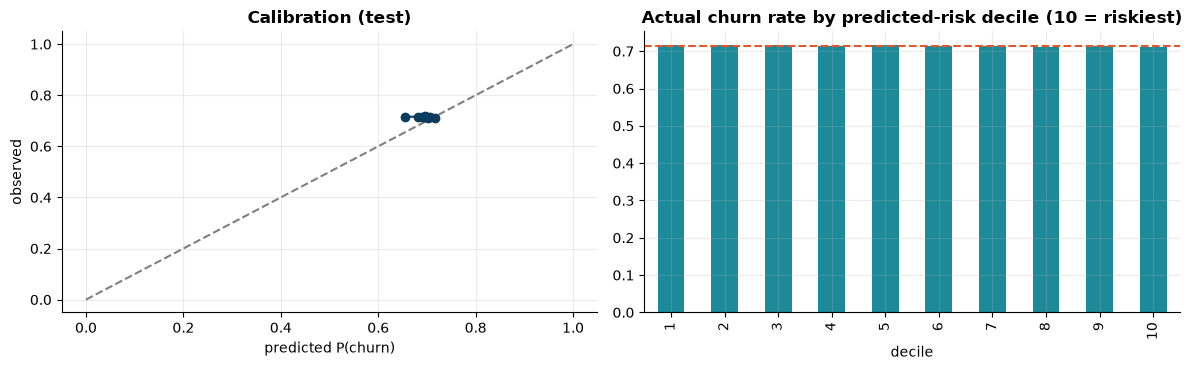

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
bins = pd.qcut(p_m, 10, duplicates="drop")
cal = pd.DataFrame({"p": p_m, "y": y}).groupby(bins, observed=True).mean()
ax[0].plot([0, 1], [0, 1], "--", color="grey"); ax[0].plot(cal.p, cal.y, "o-", color=NAVY); ax[0].set_title("Calibration (test)"); ax[0].set_xlabel("predicted P(churn)"); ax[0].set_ylabel("observed")
dec = pd.DataFrame({"p": p_m, "y": y}); dec["decile"] = pd.qcut(dec.p.rank(method="first"), 10, labels=range(1, 11))
dec.groupby("decile", observed=True).y.mean().plot.bar(ax=ax[1], color=TEAL); ax[1].set_title("Actual churn rate by predicted-risk decile (10 = riskiest)"); ax[1].axhline(y.mean(), color=RED, ls="--")
plt.tight_layout(); plt.show()

## 5 · Refit on all labelled snapshots and score everyone *today*

In [8]:
final = HistGradientBoostingClassifier(**{**hgb.get_params(), "max_iter": best}).fit(snap_df[F], snap_df.y)
cfg.save_model("churn_model", {"model": final, "features": F, "churn_days": C.CHURN_DAYS, "active_window": C.ACTIVE_WINDOW, "data_source": SOURCE})

today = C.snapshot_features(ident, last_date)
today = C.add_static(today, customers, last_date)
act = today.recency_days <= C.ACTIVE_WINDOW
today["p_churn"] = np.where(act, final.predict_proba(today[F])[:, 1], 1.0)
today["segment"] = np.where(act, "", "Lapsed (>365d)")
today.loc[act, "segment"] = C.rfm_segments(today[act]).values
today["value_at_risk_egp"] = today.p_churn * today.monetary_365
today["recommended_action"] = [C.recommended_action(s, p) for s, p in zip(today.segment, today.p_churn)]

lines = load_sales_lines()
fav = (lines[lines.customer_id.notna()].groupby(["customer_id", "category"], observed=True).quantity.sum().reset_index()
       .sort_values("quantity", ascending=False).drop_duplicates("customer_id").set_index("customer_id").category.astype(str).rename("fav_category"))
last_o = ident.groupby("customer_id").order_date.max().rename("last_order_date")
out = today.join(fav).join(last_o).reset_index()
cols = ["customer_id", "customer_segment", "age_band", "governorate_ar", "segment", "p_churn", "value_at_risk_egp", "recency_days", "freq_total", "freq_365",
        "monetary_total", "monetary_365", "aov", "fav_category", "last_order_date", "recommended_action"]
out = out[cols].copy(); out["last_order_date"] = out.last_order_date.dt.strftime("%Y-%m-%d")
cfg.save_serving("customer_scores", out.round({"p_churn": 4, "value_at_risk_egp": 1, "monetary_total": 1, "monetary_365": 1, "aov": 1}))
print(f"scored {len(out):,} customers ({act.sum():,} active in last 365d)")
seg = out[out.segment != "Lapsed (>365d)"].groupby("segment").agg(customers=("customer_id", "size"), avg_p_churn=("p_churn", "mean"),
                                                                 spend_12m_m=("monetary_365", lambda s: s.sum() / 1e6), value_at_risk_m=("value_at_risk_egp", lambda s: s.sum() / 1e6)).round(3)
seg.sort_values("value_at_risk_m", ascending=False)

scored 74,660 customers (51,597 active in last 365d)


,customers,avg_p_churn,spend_12m_m,value_at_risk_m
segment,,,,
Champions,8613,0.710,53.572,38.078
Potential loyalists,8457,0.703,48.363,33.989
Hibernating,8648,0.702,28.305,19.947
Needs attention,6156,0.702,26.833,18.912
Can't lose them,4946,0.711,25.742,18.341
Loyal,4163,0.710,22.431,15.957
At risk,7045,0.707,21.190,15.005
New customers,3569,0.694,10.367,7.265


## 6 · Where are we losing customer identities?

In [9]:
a = orders.assign(anon=orders.customer_id.isna())
by_ch = a.groupby("sales_channel").agg(orders=("anon", "size"), anon_share=("anon", "mean"), anon_revenue_m=("net_before_tax_EGP", lambda s: s[a.loc[s.index, "anon"]].sum() / 1e6)).round(3)
by_br = (a.groupby("branch_id").agg(orders=("anon", "size"), anon_share=("anon", "mean"), anon_revenue=("net_before_tax_EGP", lambda s: s[a.loc[s.index, "anon"]].sum()))
         .reset_index().merge(load_table("branches")[["branch_id", "branch_name_ar", "governorate_ar"]], on="branch_id"))
cfg.save_serving("anonymous_by_branch", by_br.round(4))
print(by_ch.to_string())
by_br.sort_values("anon_revenue", ascending=False).head(5).round(3)

                      orders  anon_share  anon_revenue_m
sales_channel                                           
E-commerce             97660       0.189          20.046
Retail POS            388171       0.191          79.143
Wholesale / reseller   54169       0.193          61.764


,branch_id,orders,anon_share,anon_revenue,branch_name_ar,governorate_ar
73,BR074,6893,0.186,2306446.61,نجع حمادي,قنا
23,BR024,6767,0.192,2263834.57,أحمد عبد العزيز,الجيزة
50,BR051,6671,0.205,2230963.00,الأردنية,الشرقية
2,BR003,6932,0.191,2226511.77,القطامية داون تاون,القاهرة
55,BR056,6952,0.188,2226075.85,سقالة,البحر الأحمر


In [10]:
# what is an identified customer worth vs an anonymous order? (supports the loyalty-capture business case)
rep = ident.groupby("customer_id").size()
print(f"identified customers: median {rep.median():.0f} orders each, {(rep > 1).mean():.1%} are repeat buyers")
print(f"extra repeat-order value if just 10% of anonymous POS orders were captured: ~EGP {a[a.anon].net_before_tax_EGP.sum() * 0.10 * (rep.mean() - 1) / 1e6:,.1f}M over the customer lifetime (rough upper bound; assumes captured customers behave like current ones)")
cfg.save_metrics("03_churn", {"test_base_rate": float(y.mean()), "model": tab.loc["HistGB (all features)"].round(4).to_dict(),
                              "baseline_logit": tab.loc["Baseline: logistic on recency/freq/spend"].round(4).to_dict(),
                              "n_scored": int(len(out)), "n_active": int(act.sum()), "avg_p_churn_active": float(out[out.segment != 'Lapsed (>365d)'].p_churn.mean()),
                              "value_at_risk_m": float(out.value_at_risk_egp.sum() / 1e6), "gap_quantiles_days": q.to_dict(),
                              "anonymous_share": float(a.anon.mean())}, DATA_DIR)

identified customers: median 5 orders each, 86.8% are repeat buyers
extra repeat-order value if just 10% of anonymous POS orders were captured: ~EGP 78.1M over the customer lifetime (rough upper bound; assumes captured customers behave like current ones)


WindowsPath('D:/HVIA Internship/task 2/cottonil-ai/artifacts/metrics/03_churn.json')

## Takeaways
* Compare the model with the **recency-only rule**: on real data, if the lift is small, simply use the rule and spend the effort on the capture/offer workflow.
* `customer_scores.csv.gz` powers the *Customer 360* tab (look up any customer, see risk, value and the suggested action).
* Biggest lever regardless of model: **capture IDs at the till** (anonymous share table above).